# Proximal gradient: composite convex objective gap
Let $f$ be convex and $L$-smooth, $L>0$, and let $g$ be closed, proper, and convex in a real finite-dimensional Euclidean space. Write $h=f+g$. Assume $x_\star$ minimizes $h$, $R\ge0$, $N\ge1$ is an integer, and $\|x_0-x_\star\|^2\le R^2$. Proximal steps and evaluations are well-defined.
$$x_{k+1}=\operatorname{prox}_{g/L}\left(x_k-\frac{1}{L}\nabla f(x_k)\right),\qquad k=0,\ldots,N-1.$$
The performance metric is $h(x_N)-h(x_\star)$.
The input supplies a candidate SOS decomposition, to be verified in subsequent certificate work; it is not imposed in this numerical model.

## Theorem and proof
Pending Block 5. Numerical evidence below is a conjecture, not an arbitrary-horizon theorem.

In [1]:
import sys
import json
from pathlib import Path

notebook_dir = Path('C:\\Users\\Jack\\Documents\\GitHub\\PEPFlow\\examples_peppy\\_evaluations\\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\\pgm_with_sos\\r01')
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary" / "helpers")]
import runtime  # noqa: E402 -- initialize private runtime after path bootstrap
import pepflow as pf  # noqa: E402 -- approved source path set above
import numpy as np  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
assert runtime.ATTEMPT == notebook_dir


In [2]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
g = pf.ConvexFunction(is_basis=True, tags=["g"])
h = (f + g).add_tag("h")

In [3]:
def make_ctx_pgm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    h.set_stationary_point("x_star")
    for i in range(int(N)):
        x = g.prox(x - f.grad(x) / L, 1 / L, tag=f"x_{i + 1}")
    f.grad(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_pgm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R * R, name="initial_condition")
    )
    pb.set_performance_metric(h(ctx[f"x_{N}"]) - h(ctx["x_star"]))
    return ctx, pb, h

ctx, pb, objective = get_pep_setup(1, {"L": 1, "R": 1})
print("Setup built:", len(ctx.basis_vectors()), "basis vectors")

Setup built: 6 basis vectors


## Numerical evidence
The saved, newly generated sweep uses CLARABEL with default settings at $L=R=1$. Its inverse values grow by approximately $4$ per step, suggesting
$$h(x_N)-h(x_\star)\le \frac{LR^2}{4N}.$$
Scaling the spatial coordinate by $R$ and function values by $LR^2$ gives this normalized candidate for $R>0$; $R=0$ starts at a minimizer. The solver statuses, including `optimal_inaccurate` at horizons 6 and 7, are retained below.

N=1: 0.2500000043; optimal
N=2: 0.1249999977; optimal
N=3: 0.0833333328; optimal
N=4: 0.0624999991; optimal
N=5: 0.0499999995; optimal
N=6: 0.0416666625; optimal_inaccurate
N=7: 0.0357142843; optimal_inaccurate
Inverse values: [ 3.99999993  8.00000015 12.00000008 16.00000024 20.00000019 24.00000241
 28.00000112]
Inverse increments: [4.00000022 3.99999993 4.00000016 3.99999996 4.00000221 3.99999871]
Maximum absolute rate residual: 4.31910757159315e-09


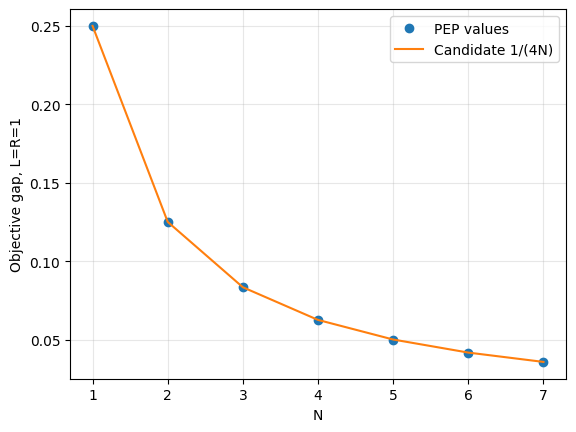

In [4]:
state = json.loads((notebook_dir / "state/pgm_b1.json").read_text())
rows = state["sweep_results"]
ns = np.array([row["N"] for row in rows])
values = np.array([row["opt_value"] for row in rows])
for row in rows:
    print(f"N={row['N']}: {row['opt_value']:.10f}; {row['status']}")
print("Inverse values:", 1 / values)
print("Inverse increments:", np.diff(1 / values))
print("Maximum absolute rate residual:", np.max(np.abs(values - 1 / (4 * ns))))
assert np.max(np.abs(values - 1 / (4 * ns))) < 1e-5
plt.plot(ns, values, "o", label="PEP values")
plt.plot(ns, 1 / (4 * ns), "-", label="Candidate 1/(4N)")
plt.xlabel("N")
plt.ylabel("Objective gap, L=R=1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Dense and relaxed proof solves
At $N=4$ the dense and relaxed PEPs use CLARABEL defaults. We retain $f$ and $g$ inequalities from the optimum to each sampled iterate and from each iterate to its successor; all other inequalities are dropped. Each chosen certificate component comes from one solve. The stored dense/relaxed data below are solver outputs, and subsequent cells recheck their full identity without resolving the optimization problem.

In [5]:
import hashlib
import sympy as sp

dense = json.loads((notebook_dir / "state/pgm_dense.json").read_text())
b2 = json.loads((notebook_dir / "state/pgm_b2.json").read_text())
N = b2["N_verify"]
print("Dense:", dense["opt_value"], dense["status"])
print("Relaxed:", b2["opt_value"], b2["certificate_provenance"]["solver_status"])
print("Dense-relaxed difference:", abs(dense["opt_value"] - b2["opt_value"]))
print("Basis:", b2["basis_vectors"])
for owner in ("f", "g"):
    entries_owner = [(name, value) for name, value in dense["duals"].items()
                     if name.startswith(owner + ":") and abs(value) > 1e-6]
    print(owner, "dense active entries:", len(entries_owner), "largest:",
          sorted(entries_owner, key=lambda row: -row[1])[:4])
print("Dense S eigenvalues:", np.linalg.eigvalsh(np.array(dense["S_matrix"])))
print("Dropped constraint count:", len(b2["relaxed_constraints"]))
for name, value in b2["named_dual_values"].items():
    if value is not None:
        print(name, value)
assert abs(dense["opt_value"] - b2["opt_value"]) < 1e-5
assert b2["certificate_provenance"]["solver_status"] == "optimal"

Dense: 0.06249999907262903 optimal
Relaxed: 0.062499998838795916 optimal
Dense-relaxed difference: 2.33833112595061e-10
Basis: ['x_0', 'x_star', 'grad_f(x_star)', 'grad_f(x_0)', 'grad_g(x_1)', 'grad_f(x_1)', 'grad_g(x_2)', 'grad_f(x_2)', 'grad_g(x_3)', 'grad_f(x_3)', 'grad_g(x_4)', 'grad_f(x_4)']
f dense active entries: 30 largest: [('f:x_3,x_4', 0.5082073393968127), ('f:x_star,x_4', 0.36041266193924903), ('f:x_2,x_4', 0.3010893217667103), ('f:x_star,x_3', 0.2707095079965974)]
g dense active entries: 16 largest: [('g:x_star,x_4', 0.48363863763526893), ('g:x_3,x_4', 0.45842033256282116), ('g:x_star,x_3', 0.2444949770855057), ('g:x_2,x_3', 0.19228714562430346)]
Dense S eigenvalues: [3.89014634e-11 1.64509903e-09 1.64513667e-09 1.01834397e-02
 1.09664953e-01 1.51109610e-01 2.49855574e-01 2.93764308e-01
 3.49255150e-01 4.16598174e-01 5.78794409e-01 2.54235277e+00]
Dropped constraint count: 34
initial_condition 0.06250000200444804
f:x_star,x_0 0.1250000524780983
f:x_star,x_1 0.1607156574709

## Lambda and S verification
Define all interpolation residuals with sign $R\le0$. The numerical certificate is
$$h(x_N)-h(x_\star)-\mathrm{opt}-\sum_q\lambda_qR_q+S=0.$$
The sum includes the radius constraint. Inequality multipliers and the Gram slack must be nonnegative and positive semidefinite, respectively.

The sparse fractions suggest $f$ successor multipliers $(i+1)/(2N-i)$ and $g$ successor multipliers $i/(2N-i)$. Optimum-to-iterate multipliers are their consecutive differences, with endpoint adjustments. The following executable definitions include all endpoints. They are candidates for arbitrary $N$, not yet an all-horizon proof. The supplied SOS aid has normalization factor 1 in this objective-gap certificate. Its positive coefficients use exact rational expressions; the notebook verifies reconstruction against the same selected numerical slack.

In [6]:
def aid_pieces(ctx, f, g, L, N):
    n = sp.S(N)
    pieces = []
    for j in range(1, int(N) + 1):
        i = sp.S(j)
        xp, x, xs = ctx[f"x_{j-1}"], ctx[f"x_{j}"], ctx["x_star"]
        ap, a, astar, s = f.grad(xp), f.grad(x), f.grad(xs), g.grad(x)
        c1 = n / ((2*n+1-i)*(2*n-i)) / L
        u1 = i/(2*n)*a + (2*n-i)/(2*n)*ap - astar
        c2 = ((i-1)/(2*n-i)*(2*n+2)/(2*n+1) + 2*n/((2*n-i)**2*(2*n+1))) / (2*L)
        u2 = ap+s-L/(2*n+1-i)*(xp-xs)
        c3 = i/(2*n+1-i)*(2*n)/(2*n+1)/(2*L)
        u3 = (2*n+1)/(2*n)*(a+s)-(ap+s)/(2*n)-L/(2*n-i)*(x-xs)
        pieces.extend([(j, 'u1', c1, u1), (j, 'u2', c2, u2), (j, 'u3', c3, u3)])
    return pieces


def multiplier_candidate(name, N):
    n = sp.S(N)
    if name == 'initial_condition':
        return sp.Rational(1, 4)/n
    owner, pair = name.split(':')
    row, col = pair.split(',')
    if col == 'x_star':
        return sp.S.Zero
    j = sp.S(int(col[2:]))
    if row == 'x_star':
        if owner == 'f':
            if j == 0:
                return 1/(2*n)
            if j == n:
                return 1/(n+1)
            return (2*n+1)/((2*n-j)*(2*n+1-j))
        if j == n:
            return 2/(n+1)
        return 2*n/((2*n-j)*(2*n+1-j))
    i = sp.S(int(row[2:]))
    if j != i+1:
        return sp.S.Zero
    return (i+1)/(2*n-i) if owner == 'f' else i/(2*n-i)


def square_sum(pieces):
    return sum((c*u**2 for _, _, c, u in pieces), pf.Scalar.zero())


In [7]:
from pepflow.parameter import eval_parameter

ctx_b2, pb_b2, obj_b2 = get_pep_setup(N, {"L": 1, "R": 1})
entries = [(c, "initial", None, None) for c in pb_b2.init_conditions]
for owner in ctx_b2.func_to_triplets:
    owner.get_interpolation_constraints(ctx_b2)
    groups = ctx_b2.get_constraint_data(owner)
    entries.extend((c, "interpolation", str(owner), str(group))
                   for group, constraints in groups.sc_dict.items() for c in constraints)
    assert not groups.psd_dict, "Unexpected PSD interpolation extras"
assert len({c.name for c, *_ in entries}) == len(entries)
assert set(b2["named_dual_values"]) == {c.name for c, *_ in entries}
assert [str(v) for v in ctx_b2.basis_vectors()] == b2["basis_vectors"]
assert [str(v) for v in ctx_b2.basis_scalars()] == b2["basis_scalars"]
for filename, expected in b2["certificate_provenance"]["source_hashes"].items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == expected
certificate_keys = ("N_verify", "params_json", "relaxed_constraints", "S_matrix", "S_row_names",
    "S_col_names", "basis_vectors", "basis_scalars", "opt_value", "tau_sol", "tau_name",
    "named_dual_values", "constraint_metadata", "normalization", "certificate_provenance",
    "numerical_checks", "numerical_decomposition")
assert hashlib.sha256(json.dumps({k: b2[k] for k in certificate_keys}, sort_keys=True,
    separators=(",", ":"), allow_nan=False).encode()).hexdigest() == b2["certificate_id"]
expected_dropped = []
for c, *_ in entries:
    if c.name == "initial_condition":
        continue
    ri, ci = c.name.split(":")[1].split(",")
    keep = ri == "x_star" or (ci != "x_star" and int(ci[2:]) == int(ri[2:]) + 1)
    if not keep:
        expected_dropped.append(c.name)
assert set(expected_dropped) == set(b2["relaxed_constraints"])
pb_b2.set_relaxed_constraints(expected_dropped)
pm = pf.ExpressionManager(ctx_b2, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
pieces = aid_pieces(ctx_b2, f, g, L, N)
S_candidate = square_sum(pieces)
E = np.array([pm.eval_vector(u).coords for _, _, _, u in pieces], dtype=float)
D = np.diag(np.asarray([eval_parameter(c, {"L": sp.S.One}) for _, _, c, _ in pieces], dtype=float))
S_saved = np.array(b2["S_matrix"])
assert np.allclose(E.T @ D @ E, S_saved, atol=1e-4, rtol=1e-5)
assert np.min(np.diag(D)) >= 0
assert np.allclose(S_saved, S_saved.T, atol=1e-6, rtol=0)
assert np.min(np.linalg.eigvalsh(S_saved)) >= -1e-6
assert all(value is None or value >= -1e-6 for value in b2["named_dual_values"].values())
weighted = pf.Scalar.zero()
weighted_exact = pf.Scalar.zero()
for c, origin, owner, group in entries:
    meta = b2["constraint_metadata"][c.name]
    assert (meta["origin"], meta["owner"], meta["group"], meta["comparator"]) == (
        origin, owner, group, c.cmp.value)
    residual = c.lhs - c.rhs
    if c.cmp == pf.Comparator.GE:
        residual = -residual
    value = b2["named_dual_values"][c.name]
    if value is not None:
        weighted += value * residual
    else:
        assert c.name in expected_dropped
    weighted_exact += multiplier_candidate(c.name, N) * residual
residual_numeric = pm.eval_scalar(pb_b2.performance_metric - b2["opt_value"] - weighted + S_candidate)
def maxabs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0))

print("Full numerical identity residuals:", maxabs(residual_numeric.inner_prod_coords),
      maxabs(residual_numeric.func_coords), maxabs(residual_numeric.offset))
assert all(maxabs(v) <= 1e-5 for v in (residual_numeric.inner_prod_coords,
    residual_numeric.func_coords, residual_numeric.offset))
print("SOS reconstruction error:", maxabs(E.T @ D @ E - S_saved))
print("Minimum S eigenvalue:", np.min(np.linalg.eigvalsh(S_saved)))
pf.pprint_labeled_matrix(E.T @ D @ E, b2["basis_vectors"], b2["basis_vectors"], precision=4)
pf.pprint_labeled_matrix(np.asarray(residual_numeric.inner_prod_coords, dtype=float),
                        b2["basis_vectors"], b2["basis_vectors"], precision=8)
# Exact-mode fixed-N check; this is separate from the numerical certificate.
exact_manager = pf.ExpressionManager(ctx_b2, resolve_parameters={"L": sp.S.One, "R": sp.S.One})
exact = exact_manager.eval_scalar(pb_b2.performance_metric - sp.Rational(1, 4*N)
    - weighted_exact + S_candidate, sympy_mode=True)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact.inner_prod_coords).flat)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact.func_coords).flat)
assert sp.simplify(exact.offset) == 0
print("Exact candidate fixed-N identity: all coordinates are zero")
for owner in ("f", "g"):
    tags = ["x_star"] + [f"x_{j}" for j in range(0 if owner == "f" else 1, N+1)]
    candidate_matrix = np.array([[sp.S.Zero if ri == ci else multiplier_candidate(
        f"{owner}:{ri},{ci}", N) for ci in tags] for ri in tags], dtype=object)
    pf.pprint_labeled_matrix(candidate_matrix, tags, tags)
candidate_error = max(abs(value - float(multiplier_candidate(name, N)))
    for name, value in b2["named_dual_values"].items() if value is not None)
assert candidate_error < 1e-4
print("Candidate multiplier error:", candidate_error)
print("Numerical certificate verified; arbitrary-horizon analytic proof remains pending.")

Full numerical identity residuals: 3.1391472977704282e-06 1.619709921740764e-08 3.165652122383289e-09
SOS reconstruction error: 3.135478371496525e-06
Minimum S eigenvalue: 2.198704447512869e-09


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Exact candidate fixed-N identity: all coordinates are zero


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Candidate multiplier error: 3.9466171285473806e-06
Numerical certificate verified; arbitrary-horizon analytic proof remains pending.


### Initial closed-form search status
Sparse consecutive multipliers were rationalized and their differences identified. Both function classes have candidate formulas, including endpoints. The supplied SOS reconstructs the same selected slack within the fixed tolerance; the candidate multipliers and SOS satisfy an exact fixed-$N$ identity above. This does not establish the identity for arbitrary horizons. Global analytic verification and the Lyapunov theorem remain pending.

## Lyapunov partial sums and ranks
For normalized interpolation residuals $I_q\le0$, define $V_0=0$ and
$$V_k=\sum_{q\text{ assigned through }k}\lambda_q I_q-\sum_{i=1}^{k}\sum_{r=1}^{3}c_{r,i}\|u_{r,i}\|^2.$$
The initial $f$ residual from $x_\star$ to $x_0$ is included in the first increment. At step $k$ add the optimum-to-$x_k$ and predecessor-to-$x_k$ residuals for both functions, then subtract the three supplied squares at $k$. Thus each increment is nonpositive. All interpolation terms and all squares are covered; the radius constraint remains for the final boundary argument.

The first observation at $N=4$ has interior rank 4 after excluding $V_0,V_N$, with absolute rank tolerance $10^{-4}$ on unscaled Gram coordinates. A second horizon is required before B3 can be completed. An $N=6$ certificate acquisition is pending in B2.

In [8]:
basis = ctx_b2.basis_vectors()
S_scalar = sum((float(S_saved[i,j])*basis[i]*basis[j]
                for i,j in np.ndindex(S_saved.shape)),pf.Scalar.zero())
saved_identity = pm.eval_scalar(pb_b2.performance_metric-b2["opt_value"]-weighted+S_scalar)
assert all(maxabs(v)<=1e-5 for v in (saved_identity.inner_prod_coords,saved_identity.func_coords,saved_identity.offset))
# Use the supplied, already reconstructed direct squares without mixing certificates.
S_piece_terms = {f"{j}:{family}": c*u**2 for j,family,c,u in pieces}
S_assignment = {name: int(name.split(':')[0])-1 for name in S_piece_terms}
piece_diff = pm.eval_scalar(sum(S_piece_terms.values(),pf.Scalar.zero()) - S_scalar)
assert all(maxabs(v) <= 1e-5 for v in (piece_diff.inner_prod_coords,piece_diff.func_coords,piece_diff.offset))
for piece in S_piece_terms.values():
    coords = pm.eval_scalar(piece)
    assert maxabs(coords.func_coords) <= 1e-5 and maxabs(coords.offset) <= 1e-5
    matrix = np.asarray(coords.inner_prod_coords,dtype=float)
    assert np.linalg.eigvalsh((matrix+matrix.T)/2).min() >= -1e-6

# Normalized interpolation residuals are <=0; subtracting each PSD square gives a nonincreasing sequence.
group_terms = {}
term_assignment = {}
for c, origin, _, _ in entries:
    if c.name == 'initial_condition' or b2['named_dual_values'][c.name] is None:
        continue
    assert origin == 'interpolation'
    residual = c.lhs-c.rhs
    if c.cmp == pf.Comparator.GE:
        residual = -residual
    group_terms[c.name] = b2['named_dual_values'][c.name]*residual
    row,col = c.name.split(':')[1].split(',')
    j = int(col[2:])
    term_assignment[c.name] = -1 if j==0 else j-1
assert set(term_assignment) == set(group_terms)
assert set(S_assignment) == set(S_piece_terms)
lyap = [pf.Scalar.zero()]
partial_sum = sum((group_terms[name] for name,target in term_assignment.items() if target == -1),pf.Scalar.zero())
for step in range(N):
    partial_sum += sum((group_terms[name] for name,target in term_assignment.items() if target == step),pf.Scalar.zero())
    partial_sum -= sum((S_piece_terms[name] for name,target in S_assignment.items() if target == step),pf.Scalar.zero())
    lyap.append(partial_sum)
rank_tolerance = 1e-4
rank_left,rank_right = 1,1
ranks=[]
singular_values=[]
for k,Vk in enumerate(lyap):
    matrix=np.asarray(pm.eval_scalar(Vk).inner_prod_coords,dtype=float)
    sv=np.linalg.svd(matrix,compute_uv=False)
    singular_values.append(sv.tolist())
    rank=int(np.linalg.matrix_rank(matrix,tol=rank_tolerance))
    ranks.append(rank)
    print(f'rank V_{k}: {rank}')
    if k==0:
        print()
retained=ranks[rank_left:N+1-rank_right]
print('Interior rank is constant at this N:',len(retained)>=3 and len(set(retained))==1,'boundary exclusions:',(rank_left,rank_right))
coverage = lyap[N] - (sum(group_terms.values(),pf.Scalar.zero())-S_scalar)
coverage_eval=pm.eval_scalar(coverage)
coverage_residual=max(maxabs(v) for v in (coverage_eval.inner_prod_coords,coverage_eval.func_coords,coverage_eval.offset))
assert coverage_residual <= 1e-5
increment_residuals=[]
for k in range(N):
    assigned={-1,0} if k==0 else {k}
    increment=sum((group_terms[name] for name,step in term_assignment.items() if step in assigned),pf.Scalar.zero())
    increment-=sum((S_piece_terms[name] for name,step in S_assignment.items() if step in assigned),pf.Scalar.zero())
    ev=pm.eval_scalar(lyap[k+1]-lyap[k]-increment)
    error=max(maxabs(v) for v in (ev.inner_prod_coords,ev.func_coords,ev.offset))
    increment_residuals.append(error)
    assert error <= 1e-5
grouping_checked=True
print('Full-coordinate coverage residual:',coverage_residual)


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 1
Interior rank is constant at this N: True boundary exclusions: (1, 1)


Full-coordinate coverage residual:

 3.1354783715242807e-06


## Identify the vectors composing the Lyapunov function
Pending Block 4.

## Coefficients and exact identities
Pending Blocks 4 and 5.